# Kiểm chứng artifact và benchmark FPT v2

Notebook chỉ nạp artifact của lượt train đã khóa, **không huấn luyện và không chọn lại bằng test**.
Kiểm tra hash dữ liệu/weights và đối chiếu metrics tính lại với manifest.
Năm 2025 là đánh giá lịch sử đã được xem trong các lần thử trước.

**GitHub/Colab v2:** setup tự clone nhánh `feature/train-model` vào thư mục riêng, cài môi trường và phục hồi snapshot có hash. Nếu Colab yêu cầu restart sau cài thư viện, restart session rồi Run all lại. Không mở notebook cũ trong Drive để lấy kết quả chính thức.

## 1. Nạp lượt chạy đã lưu

In [1]:
from pathlib import Path
import os, sys, json, subprocess, importlib.metadata
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    ROOT = Path('/content/Stock_Prediction_Project_v2')
    if not (ROOT / '.git').exists():
        subprocess.check_call(['git', 'clone', '--depth', '1', '--branch', 'feature/train-model',
                               'https://github.com/PhucTruong11/FPT_Stock_Forecasting.git', str(ROOT)])
    loaded_versions = {name: getattr(sys.modules.get(name), '__version__', None)
                       for name in ['numpy', 'pandas', 'sklearn', 'tensorflow', 'xgboost']}
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', '-r', str(ROOT / 'requirements-colab.txt')])
    packages = {'sklearn': 'scikit-learn', 'numpy': 'numpy', 'pandas': 'pandas', 'tensorflow': 'tensorflow', 'xgboost': 'xgboost'}
    changed = [name for name, old in loaded_versions.items()
               if old is not None and old != importlib.metadata.version(packages[name])]
    if changed:
        raise RuntimeError('Dependencies changed: ' + str(changed) + '. Restart the Colab session, then Run all again.')
else:
    candidates = [Path(os.environ.get('FPT_PROJECT_ROOT', Path.cwd())), Path.cwd(), *Path.cwd().parents]
    ROOT = next((p for p in candidates if (p / 'src/models/experiment.py').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Open the complete updated project.')
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.data.snapshot import restore_snapshot
restore_snapshot(ROOT)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.models.experiment import load_data, split_masks, run_experiment, evaluate_saved
from src.features.build_features import FEATURE_COLUMNS, TARGET_COLUMN
plt.rcParams.update({'figure.figsize': (11, 4), 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
print('Project:', ROOT)
print('Exact shared snapshot restored; no Yahoo download.')


Project: D:\Dev\Subject_Uni\Machine_Learning\Stock_Prediction_Project
Exact shared snapshot restored; no Yahoo download.


In [2]:
pointer = json.loads((ROOT / 'models/latest_experiment.json').read_text())
ARTIFACT_DIR, REPORT_DIR = ROOT / pointer['artifact_dir'], ROOT / pointer['report_dir']
manifest = json.loads((ARTIFACT_DIR / 'manifest.json').read_text())
scores, predictions = evaluate_saved(ARTIFACT_DIR, ROOT, verify_recorded=True)
display(scores)
print('Reloaded metrics match the saved record:', pointer['run_id'])

,model,split,n,rmse,mae,hit_rate_pct,nonzero_actual_n,neutral_actual_n,direction_coverage_pct,mse_skill_vs_zero
0,Zero-Return,validation,493,0.014095,0.010102,NaN,464,29,0.000000,0.000000
1,Return Persistence,validation,493,0.019069,0.014454,48.922414,464,29,94.612069,-0.830358
2,Train Mean,validation,493,0.013981,0.010076,54.741379,464,29,100.000000,0.016065
3,Always Up,validation,493,0.017470,0.014261,54.741379,464,29,100.000000,-0.536258
4,Linear Regression,validation,493,0.014051,0.010104,51.724138,464,29,100.000000,0.006176
5,Ridge,validation,493,0.014035,0.010085,50.646552,464,29,100.000000,0.008466
6,XGBoost,validation,493,0.014046,0.010060,56.034483,464,29,100.000000,0.006947
7,LSTM,validation,493,0.014033,0.009997,54.741379,464,29,100.000000,0.008832
8,Zero-Return,test,248,0.019917,0.013146,NaN,211,37,0.000000,0.000000
9,Return Persistence,test,248,0.027995,0.021221,36.018957,211,37,83.412322,-0.975684


Reloaded metrics match the saved record: 20261025T121448987851Z


## 2. Sai số và độ chính xác chiều tăng/giảm

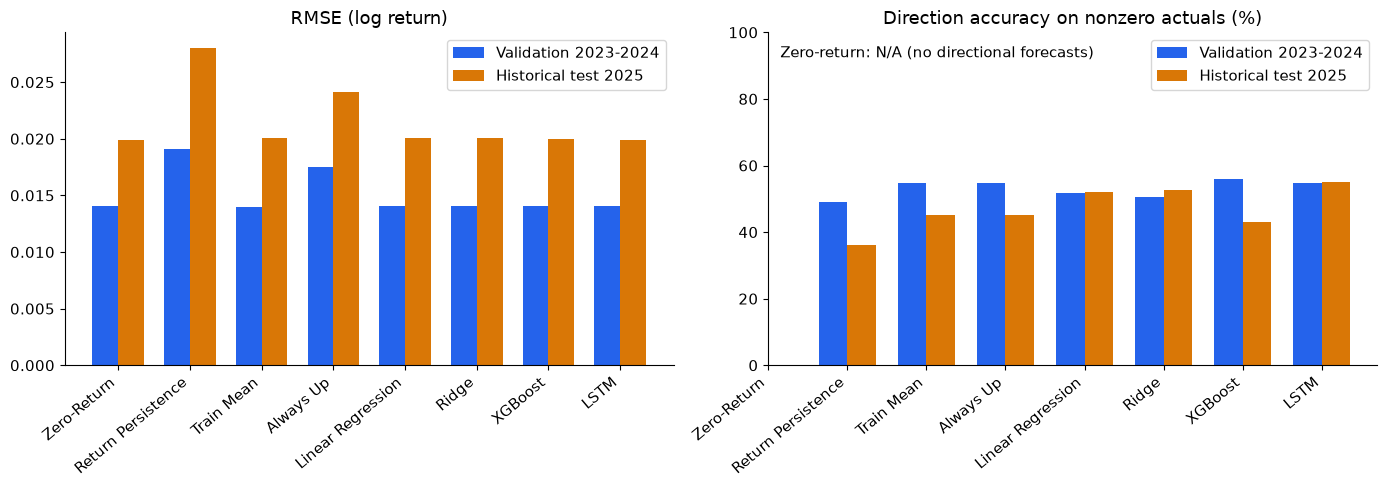

In [3]:
names = scores.loc[scores['split'].eq('validation'), 'model'].tolist()
val = scores.loc[scores['split'].eq('validation')].set_index('model').loc[names]
test = scores.loc[scores['split'].eq('test')].set_index('model').loc[names]
x = np.arange(len(names))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric, title in [(axes[0], 'rmse', 'RMSE (log return)'),
                          (axes[1], 'hit_rate_pct', 'Direction accuracy on nonzero actuals (%)')]:
    ax.bar(x - .18, val[metric], .36, label='Validation 2023-2024', color='#2563eb')
    ax.bar(x + .18, test[metric], .36, label='Historical test 2025', color='#d97706')
    ax.set_xticks(x, names, rotation=40, ha='right')
    ax.set_title(title)
    ax.set_ylim(bottom=0)
    ax.legend()
axes[1].set_ylim(0, 100)
axes[1].text(0.02, .96, 'Zero-return: N/A (no directional forecasts)', transform=axes[1].transAxes, va='top')
fig.tight_layout()
fig.savefig(REPORT_DIR / 'benchmark.png', dpi=160)
plt.show()

## 3. Phân tích lỗi theo thời gian

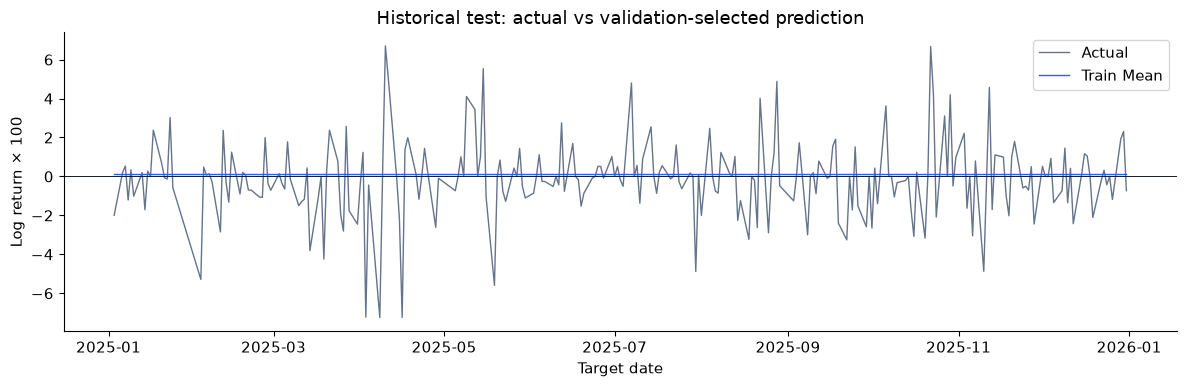

,Date,Target_Date_1d,Target_Return_1d,predicted_log_return,absolute_error
4501,2025-04-04,2025-04-08,-0.072476,0.001159,0.073635
4507,2025-04-15,2025-04-16,-0.072385,0.001159,0.073544
4499,2025-04-02,2025-04-03,-0.072218,0.001159,0.073377
4503,2025-04-09,2025-04-10,0.067028,0.001159,0.065869
4637,2025-10-21,2025-10-22,0.066691,0.001159,0.065532
4527,2025-05-16,2025-05-19,-0.055936,0.001159,0.057095
4525,2025-05-14,2025-05-15,0.055344,0.001159,0.054184
4456,2025-01-24,2025-02-03,-0.052873,0.001159,0.054032
4579,2025-07-29,2025-07-30,-0.048790,0.001159,0.049949
4504,2025-04-10,2025-04-11,0.051071,0.001159,0.049912


In [4]:
chosen = manifest['selection']['selected_model']
frame = predictions.loc[predictions['split'].eq('test') & predictions['model'].eq(chosen)].copy()
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(pd.to_datetime(frame['Target_Date_1d']), frame[TARGET_COLUMN] * 100,
        label='Actual', color='#64748b', linewidth=1)
ax.plot(pd.to_datetime(frame['Target_Date_1d']), frame['predicted_log_return'] * 100,
        label=chosen, color='#2563eb', linewidth=1)
ax.axhline(0, color='#111827', linewidth=.7)
ax.set(xlabel='Target date', ylabel='Log return × 100', title='Historical test: actual vs validation-selected prediction')
ax.legend()
fig.tight_layout()
fig.savefig(REPORT_DIR / 'test_returns.png', dpi=160)
plt.show()
frame['absolute_error'] = abs(frame[TARGET_COLUMN] - frame['predicted_log_return'])
display(frame.nlargest(10, 'absolute_error')[['Date', 'Target_Date_1d', TARGET_COLUMN, 'predicted_log_return', 'absolute_error']])

## 4. Chẩn đoán lệch lớp sau thực nghiệm

Bảng này giúp diễn giải Hit Rate, không được dùng để chọn lại model hoặc siêu tham số. Always-down bên dưới là mốc đối chiếu hậu nghiệm, không phải model được chọn trên validation.

In [5]:
diagnostics = []
for name, group in predictions.loc[predictions['split'].eq('test')].groupby('model', sort=False):
    actual, pred = group[TARGET_COLUMN].to_numpy(), group['predicted_log_return'].to_numpy()
    up, down = actual > 0, actual < 0
    up_recall = float((pred[up] > 0).mean())
    down_recall = float((pred[down] < 0).mean())
    diagnostics.append({'model': name, 'actual_up_n': int(up.sum()), 'actual_down_n': int(down.sum()),
                        'predicted_up_n': int((pred > 0).sum()), 'predicted_down_n': int((pred < 0).sum()),
                        'up_recall_pct': 100 * up_recall, 'down_recall_pct': 100 * down_recall,
                        'balanced_accuracy_pct': 50 * (up_recall + down_recall) if (pred != 0).any() else np.nan})
diagnostics = pd.DataFrame(diagnostics)
diagnostics.to_csv(REPORT_DIR / 'direction_diagnostics.csv', index=False)
display(diagnostics)
nonzero_actual = frame.loc[frame[TARGET_COLUMN].ne(0), TARGET_COLUMN]
print(f'Post-hoc always-down reference: {(nonzero_actual < 0).mean():.2%}')
print('This reference does not change the validation-selected model.')

,model,actual_up_n,actual_down_n,predicted_up_n,predicted_down_n,up_recall_pct,down_recall_pct,balanced_accuracy_pct
0,Zero-Return,95,116,0,0,0.000000,0.000000,NaN
1,Return Persistence,95,116,95,116,28.421053,42.241379,35.331216
2,Train Mean,95,116,248,0,100.000000,0.000000,50.000000
3,Always Up,95,116,248,0,100.000000,0.000000,50.000000
4,Linear Regression,95,116,166,82,71.578947,36.206897,53.892922
5,Ridge,95,116,172,76,73.684211,35.344828,54.514519
6,XGBoost,95,116,189,59,72.631579,18.965517,45.798548
7,LSTM,95,116,152,96,68.421053,43.965517,56.193285


Post-hoc always-down reference: 54.98%
This reference does not change the validation-selected model.


## Giới hạn

- Giá điều chỉnh tải sau thời kỳ nghiên cứu; lịch phiên chưa xác minh độc lập với HOSE.
- Không gọi 2025 là test hoàn toàn chưa từng xem.
- Directional accuracy không phải xác suất đúng của mỗi dự báo, không chứng minh hiệu quả giao dịch.
- Một lần chia lịch sử chưa chứng minh khả năng tổng quát ở mọi giai đoạn; walk-forward là bước tiếp theo.
- `reports/figures` cũ không phải nguồn cho các con số của lượt chạy mới.